# Gravity observations: reference, units and plate scale

**Question:** For the authored station control at 45° latitude and 1 km elevation, what Bouguer disturbance follows from the declared WGS84 reference and 2670 kg/m³ infinite-plate assumption?

**Level 1 · Prerequisites: none; estimated reading time: 35 minutes.**

## Objectives

Trace the physical meaning and units of a reference disturbance and an infinite-plate correction using the product station pipeline.

## Setup

Use the repository's pinned Python 3.12 environment. Build it from the repository root with `scripts/setup.ps1 -Notebooks` on Windows or `scripts/setup.sh --notebooks` on Linux/macOS. This command is shown for reference; the notebook does not install packages.

```text
pip install boule==0.5.0 harmonica==0.7.0
```

Import the product method and plotting tools once. The next cell reports the active implementation.

In [1]:
# Import the M01 pipeline and plotting tools.
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd().parents[2]
sys.path.insert(0, str(root / 'data-pipeline'))
from gravity_processing import process_survey
from importlib.metadata import version
print('Boule:', version('boule'), '| Harmonica:', version('harmonica'))
print('Pipeline:', Path(process_survey.__code__.co_filename).name)


Boule: 0.5.0 | Harmonica: 0.7.0
Pipeline: gravity_processing.py


## Data

The only station is a committed, authored analytic control at latitude 45°, receiver and surface heights 1000 m, and absolute gravity 980435.2584487502 mGal. Its receipt identifies synthetic provenance and Apache-2.0 rights; it is not a field observation. The notebook reads `docs/methods/gravity-processing/examples/station-control.json`. Product processing uses Boule’s WGS84 normal gravity and Harmonica’s infinite plate calculation through `data-pipeline/gravity_processing.py`. The control assumes tide-free gravity, ellipsoidal height, upward-positive height and downward-positive gravity.

Read the declared inputs or construct the authored synthetic geometry. No solver output is loaded.

In [2]:
# Read committed analytic control and retain its provenance metadata.
from copy import deepcopy
import json
control_path = root / 'docs/methods/gravity-processing/examples/station-control.json'
request = json.loads(control_path.read_text(encoding='utf-8'))
source = request['dataset']
config = request['config']
print(source['metadata']['source_kind'], source['metadata']['rights'])
print(source['metadata']['height_datum'], source['metadata']['gravity_unit'])


synthetic_control Authored numerical control, Apache-2.0
ellipsoidal mGal


## Method

### Define the measurand before correcting it

Absolute gravity, gravity disturbance and Bouguer disturbance are different quantities. The product pipeline starts with calibrated absolute gravity, converts sign and units into its canonical convention, references normal gravity, then applies the infinite plate only when its inputs are declared. A station label or a plausible-looking magnitude cannot establish which quantity a file contains.

### Normal gravity is latitude and height dependent

Write D=g−γ(φ,h), with observed gravity g, geodetic latitude φ, ellipsoidal height h, and the WGS84 normal field γ. The reference model matters: subtracting a normal value at the wrong latitude or height produces a systematic offset that can masquerade as geology. Boule supplies the WGS84 closed-form normal field used by this pipeline; it is not a local geoid or a terrain model.

### Plate attraction is a separate approximation

For an ideal infinite horizontal slab, B=2πGρt. G in m³ kg⁻¹ s⁻², density ρ in kg/m³ and thickness t in m yield acceleration; multiplying by 10⁵ converts m/s² to mGal. A surface height supplied to the plate term is not identical to receiver elevation. The approximation assumes a laterally infinite plate and cannot replace a DEM-based terrain correction (USGS TM 2-D4; Harmonica API).

### Follow the ordered transformations

The product records ordered stage increments and resulting state. Observing the increments is more informative than receiving one final number: it reveals whether the reference and plate operations occurred and supports replay. This synthetic one-station control has no instrument drift or tide to estimate. Its metadata marks both as not applicable rather than silently treating unknown corrections as zero.

### Interpret the magnitude, not just the answer

The final disturbance answers the numerical question only under the declared ellipsoid, datum, signs, surface height and plate density. A real survey would also require source rights, calibration, drift, tides, datum conversion, terrain treatment and spatial QA. The notebook therefore demonstrates the pipeline contract and dimensional reasoning without asserting that the result describes a place on Earth.

Run the WGS84 reference stage alone to isolate normal-gravity effect.

In [3]:
# Execute the product station-processing API for disturbance.
stage_config = {**config, 'target': 'gravity_disturbance'}
disturbance_result = process_survey(deepcopy(source), stage_config)
value_mgal = disturbance_result['qc']['derived_mgal'][0]
print('disturbance:', disturbance_result['dataset']['state'], value_mgal, 'mGal')

disturbance: gravity_disturbance 123.96875606756657 mGal


Run the declared full target; inspect the actual plate increment and conditional uncertainty.

In [4]:
# Execute the product station-processing API for bouguer.
stage_config = {**config, 'target': 'bouguer_disturbance'}
bouguer_result = process_survey(deepcopy(source), stage_config)
value_mgal = bouguer_result['qc']['derived_mgal'][0]
print('bouguer:', bouguer_result['dataset']['state'], value_mgal, 'mGal')

bouguer: bouguer_disturbance 12.000000000024315 mGal


Change only uncertainty aggregation; keep all physical source values fixed.

In [5]:
# Execute the product station-processing API for independent.
stage_config = {**config, 'target': 'bouguer_disturbance', 'uncertainty_model': 'independent_first_order'}
independent_result = process_survey(deepcopy(source), stage_config)
value_mgal = independent_result['qc']['derived_mgal'][0]
print('independent:', independent_result['dataset']['state'], value_mgal, 'mGal')

independent: bouguer_disturbance 12.000000000024315 mGal


Plot actual reference and plate-corrected outputs on the same scale to expose the correction.

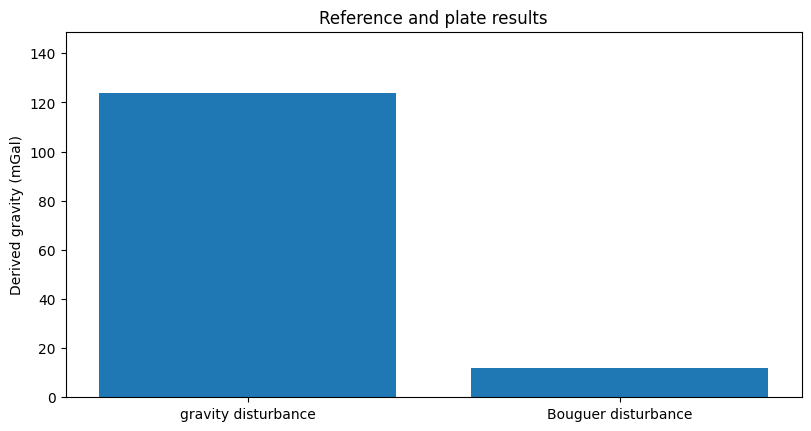

In [6]:
# Compare derived quantities without letting absolute gravity flatten the anomaly scale.
fig, ax = plt.subplots(figsize=(8, 4.2), constrained_layout=True)
values = [disturbance_result['qc']['derived_mgal'][0], bouguer_result['qc']['derived_mgal'][0]]
ax.bar(['gravity disturbance', 'Bouguer disturbance'], values)
ax.set_ylim(0.0, max(values) * 1.2)
ax.set(ylabel='Derived gravity (mGal)', title='Reference and plate results')
plt.show()

The bars compare the two computed derived quantities on an anomaly-scale axis: the WGS84 gravity disturbance and the Bouguer disturbance after plate removal. Absolute gravity is omitted from the plotted range because its roughly 980,000 mGal magnitude would make both anomalies unreadable. The plot therefore highlights the physical corrections without implying a spatial survey.

Compare the two uncertainty policies after the physical result. The next figure carries their conditional standard deviations.

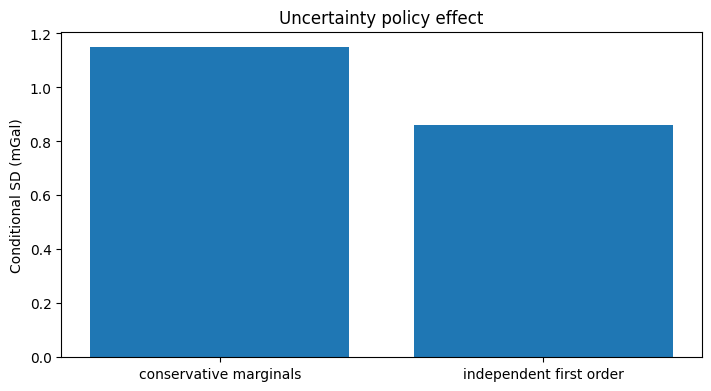

In [7]:
# Plot uncertainty returned by executions with identical physical inputs.
fig, ax = plt.subplots(figsize=(7, 3.8), constrained_layout=True)
values = [bouguer_result['processing']['uncertainty_mgal'][0],
          independent_result['processing']['uncertainty_mgal'][0]]
ax.bar(['conservative marginals', 'independent first order'], values)
ax.set(ylabel='Conditional SD (mGal)', title='Uncertainty policy effect')
plt.show()
policy_gap = abs(values[0] - values[1])

The bars show the absolute station value and the ordered pipeline additions on a common mGal axis; the point marker is the computed Bouguer disturbance. The chart explains how the large reference gravity is reduced by distinct terms rather than hiding them inside a final anomaly. A single analytic station cannot validate regional geology, terrain correction, datum accuracy or field eligibility.

The uncertainty bars compare conditional propagation policies, not alternative corrected values. Their spread is driven by treatment of declared marginal inputs; this one-station result cannot reveal spatial correlation or model error.

## Results

**Answer:** The pipeline computes 12.000000000024315 mGal Bouguer disturbance. Its two declared uncertainty policies differ by 0.28846679391806507 mGal; neither result is field acceptance.

In [8]:
# Report computed value, uncertainty difference and scope flag.
print({'bouguer_mgal': bouguer_result['qc']['derived_mgal'][0],
       'uncertainty_policy_gap_mgal': policy_gap,
       'full_method_accepted': bouguer_result['processing']['full_method_accepted']})

{'bouguer_mgal': 12.000000000024315, 'uncertainty_policy_gap_mgal': 0.28846679391806507, 'full_method_accepted': False}


## Summary

Gravity processing begins with quantity, reference, sign, units and datum. The infinite-plate term is a declared approximation, not a general terrain correction. Preserve each stage and its provenance, and do not promote this analytic control to field evidence.

## References

- https://pubs.usgs.gov/tm/02/d04/tm2d4.pdf
- https://www.fatiando.org/harmonica/latest/api/index.html